In [8]:
!wget -q https://archive.ics.uci.edu/static/public/222/bank+marketing.zip -O bank.zip
!unzip -o -q bank.zip -d bank_raw
!unzip -o -q bank_raw/bank.zip -d bank_raw/bank
import glob; print(glob.glob("bank_raw/**/bank-full.csv", recursive=True))

['bank_raw/bank/bank-full.csv']


seed 0 done
seed 1 done
seed 2 done
seed 3 done
seed 4 done
seed 5 done
seed 6 done
seed 7 done
seed 8 done
seed 9 done

NMI mean ± std:
                            mean    std
method              c                 
AFIMVC              0.00  0.666  0.057
                    0.01  0.666  0.058
                    0.05  0.661  0.057
                    0.10  0.635  0.061
                    0.20  0.558  0.065
AFIMVC+robust_mu0.1 0.00  0.692  0.039
                    0.01  0.691  0.042
                    0.05  0.682  0.041
                    0.10  0.670  0.047
                    0.20  0.590  0.044
AFIMVC+robust_mu1   0.00  0.639  0.162
                    0.01  0.640  0.163
                    0.05  0.635  0.161
                    0.10  0.621  0.151
                    0.20  0.589  0.129
AFIMVC+robust_mu10  0.00  0.453  0.153
                    0.01  0.454  0.154
                    0.05  0.447  0.150
                    0.10  0.436  0.142
                    0.20  0.398  0.130

FLI

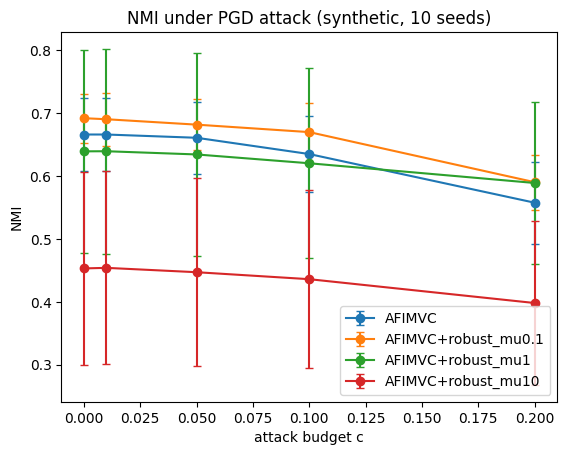


Bank Marketing k-means NMI (term-deposit label): 0.037


In [9]:
# ============ SETUP ============
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from scipy.stats import ttest_rel
from sklearn.metrics import normalized_mutual_info_score as nmi, adjusted_rand_score as ari
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans

dev = "cuda" if torch.cuda.is_available() else "cpu"
torch.backends.cudnn.deterministic = True

ATTACK_SAMP, ATTACK_STEPS, ATTACK_STEP = 1.0, 20, 0.5
ATTACK_C = [0, 0.01, 0.05, 0.1, 0.2]
MU_SMALL = 0.1
MU_GRID = [0.1, 1.0, 10.0]

# ============ 1. SYNTHETIC DATA ============
def make_data(N=2000, d=20, K=2, seed=0):
    rng = np.random.default_rng(seed)
    y = rng.integers(0, K, N)
    s = rng.integers(0, 2, N)
    X0 = rng.normal(size=(N, d)) + 1.5 * y[:, None] + 0.8 * s[:, None]
    X0 = StandardScaler().fit_transform(X0)
    v1 = StandardScaler().fit_transform(np.tanh(X0))
    gmm = GaussianMixture(K, random_state=seed).fit(X0)
    v2 = StandardScaler().fit_transform(gmm.predict_proba(X0))
    v2 = np.hstack([v2, rng.normal(size=(N, d - K))])
    return [torch.tensor(v1, dtype=torch.float32), torch.tensor(v2, dtype=torch.float32)], y, s

def make_masks(N, V, missing_rate, seed=0):
    g = torch.Generator().manual_seed(seed)
    M = (torch.rand(N, V, generator=g) > missing_rate).float()
    M[M.sum(1) == 0, 0] = 1.0
    return M

# ============ 2. MODEL ============
class GRL(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, lam): ctx.lam = lam; return x.view_as(x)
    @staticmethod
    def backward(ctx, g): return -ctx.lam * g, None

class AFIMVC(nn.Module):
    def __init__(self, dims, dh=32, K=2):
        super().__init__()
        self.enc = nn.ModuleList([nn.Sequential(nn.Linear(d, 64), nn.ReLU(), nn.Linear(64, dh)) for d in dims])
        self.dec = nn.ModuleList([nn.Sequential(nn.Linear(dh, 64), nn.ReLU(), nn.Linear(64, d)) for d in dims])
        self.adv = nn.Sequential(nn.Linear(dh, 32), nn.ReLU(), nn.Linear(32, 1))
        self.centroids = nn.Parameter(torch.randn(K, dh) * 0.1)

    def encode(self, views, masks):
        H = [e(x) * m[:, None] for e, x, m in zip(self.enc, views, masks.T)]
        Hs = torch.stack(H, 1)
        cnt = masks.sum(1, keepdim=True).clamp_min(1)
        return Hs.sum(1) / cnt, H

    def forward(self, views, masks):
        Hbar, _ = self.encode(views, masks)
        return F.softmax(-torch.cdist(Hbar, self.centroids) ** 2, dim=1)

    def recon(self, views):
        return sum(F.mse_loss(d(e(x)), x) for e, d, x in zip(self.enc, self.dec, views))

def afimvc_loss(model, views, masks, s, lam_adv=0.5):
    Hbar, H = model.encode(views, masks)
    P = F.softmax(-torch.cdist(Hbar, model.centroids) ** 2, 1)
    L_re = model.recon(views)
    L_fa = sum(F.mse_loss(H[u], H[v]) for u in range(len(H)) for v in range(u + 1, len(H)))
    p_bar = P.mean(0)
    L_bal = (p_bar * p_bar.clamp_min(1e-8).log()).sum()
    L_clu = -(P * P.clamp_min(1e-8).log()).sum(1).mean()
    logit = model.adv(GRL.apply(Hbar, 1.0)).squeeze(1)
    L_adv = F.binary_cross_entropy_with_logits(logit, s.float())
    return L_re + 0.1 * L_fa + 0.1 * L_clu + 1.0 * L_bal + lam_adv * L_adv

# ============ 3. ATTACK ============
def project_l2(d, eps):
    n = d.norm(dim=1, keepdim=True).clamp_min(1e-12)
    return d * torch.clamp(eps / n, max=1.0)

def attack_mask(masks, samp_frac=0.1, view_frac=0.5):
    B, V = masks.shape
    samp = (torch.rand(B, 1, device=masks.device) < samp_frac).float()
    k = max(1, int(round(view_frac * V)))
    idx = torch.rand(B, V, device=masks.device).argsort(1)[:, :k]
    vsel = torch.zeros_like(masks).scatter_(1, idx, 1.0)
    return samp * vsel * masks

def pgd_l2(model, views, masks, c, samp_frac=0.1, steps=10, step=0.25):
    if c == 0: return views
    model.eval()
    with torch.no_grad(): P_clean = model(views, masks)
    A = attack_mask(masks, samp_frac=samp_frac)
    eps = [c * np.sqrt(x.shape[1]) for x in views]
    deltas = [project_l2(torch.randn_like(x), e) * A[:, [v]] for v, (x, e) in enumerate(zip(views, eps))]
    for _ in range(steps):
        for d in deltas: d.requires_grad_(True)
        P_adv = model([x + d for x, d in zip(views, deltas)], masks)
        loss = F.kl_div(P_adv.clamp_min(1e-8).log(), P_clean, reduction='batchmean')
        grads = torch.autograd.grad(loss, deltas)
        with torch.no_grad():
            deltas = [project_l2(d + step * e * g / (g.norm(dim=1, keepdim=True) + 1e-12), e) * A[:, [v]]
                      for v, (d, g, e) in enumerate(zip(deltas, grads, eps))]
    model.train()
    return [(x + d).detach() for x, d in zip(views, deltas)]

def robust_loss(model, views, masks, c, mu=1.0, samp_frac=1.0, steps=20, step=0.5):
    P_clean = model(views, masks)
    adv = pgd_l2(model, views, masks, c, samp_frac=samp_frac, steps=steps, step=step)
    P_adv = model(adv, masks)
    return mu * F.kl_div(P_adv.clamp_min(1e-8).log(), P_clean, reduction='batchmean')

# ============ 4. TRAIN / EVALUATE ============
def cluster_acc(y, p):
    K = max(y.max(), p.max()) + 1; w = np.zeros((K, K), int)
    for a, b in zip(p, y): w[a, b] += 1
    r, c_ = linear_sum_assignment(-w); return w[r, c_].sum() / len(y)

def balance(p, s):
    vals = []
    for k in np.unique(p):
        m = p == k; n1, n0 = (s[m] == 1).sum(), (s[m] == 0).sum()
        if n0 == 0 or n1 == 0: return 0.0
        vals.append(min(n0 / n1, n1 / n0))
    return min(vals)

def train(views, masks, s, y, use_robust, c_train=0.1, mu=1.0,
          max_epochs=600, patience=100, seed=0):
    torch.manual_seed(seed)
    model = AFIMVC([v.shape[1] for v in views]).to(dev)
    views = [v.to(dev) for v in views]; masks = masks.to(dev); s_t = torch.tensor(s).to(dev)
    with torch.no_grad():
        Hbar, _ = model.encode(views, masks)
        km = KMeans(2, n_init=10, random_state=seed).fit(Hbar.cpu().numpy())
        model.centroids.data = torch.tensor(km.cluster_centers_, dtype=torch.float32, device=dev)
    opt = torch.optim.Adam(model.parameters(), 1e-3)
    best, best_state, since_best = -1, None, 0
    for ep in range(max_epochs):
        model.train()
        loss = afimvc_loss(model, views, masks, s_t)
        if use_robust:
            loss = loss + robust_loss(model, views, masks, c_train, mu,
                                      samp_frac=ATTACK_SAMP, steps=ATTACK_STEPS, step=ATTACK_STEP)
        opt.zero_grad(); loss.backward(); opt.step()
        if ep % 25 == 0 or ep == max_epochs - 1:
            with torch.no_grad():
                p = model(views, masks).argmax(1).cpu().numpy()
            score = nmi(y, p)
            if score > best + 1e-3:
                best, since_best = score, 0
                best_state = {k: v.clone() for k, v in model.state_dict().items()}
            else:
                since_best += 25
            if since_best >= patience: break
    if best_state is not None: model.load_state_dict(best_state)
    return model

@torch.no_grad()
def predict(model, views, masks):
    model.eval(); return model(views, masks).argmax(1).cpu().numpy()

def evaluate(model, views, masks, y, s, c):
    clean = predict(model, [v.to(dev) for v in views], masks.to(dev))
    views_adv = pgd_l2(model, [v.to(dev) for v in views], masks.to(dev), c,
                       samp_frac=ATTACK_SAMP, steps=ATTACK_STEPS, step=ATTACK_STEP)
    p = predict(model, views_adv, masks.to(dev))
    return dict(NMI=nmi(y, p), ARI=ari(y, p), ACC=cluster_acc(y, p),
                BAL=balance(p, s), FLIP=float((p != clean).mean()))

# ============ 5. 10-SEED COMPARISON ============
results = []
for seed in range(10):
    views, y, s = make_data(seed=seed)
    masks = make_masks(len(y), len(views), 0.25, seed=seed)
    runs = [("AFIMVC", 0.0, train(views, masks, s, y, False, seed=seed))]
    for mu in MU_GRID:
        runs.append((f"AFIMVC+robust_mu{mu:g}", mu,
                     train(views, masks, s, y, True, mu=mu, seed=seed)))
    for method, mu, model in runs:
        for c in ATTACK_C:
            r = evaluate(model, views, masks, y, s, c)
            results.append(dict(method=method, mu=mu, seed=seed, c=c, **r))
    print(f"seed {seed} done")

df = pd.DataFrame(results)
df.to_csv("results.csv", index=False)
df.groupby(["method", "c"])["NMI"].agg(["mean", "std"]).round(3).to_csv("table_nmi_10seed.csv")
flip = df.groupby(["method", "c"])["FLIP"].mean().unstack().round(3)
flip.to_csv("table_flip_rate.csv")
print("\nNMI mean ± std:\n", df.groupby(["method", "c"])["NMI"].agg(["mean", "std"]).round(3))
print("\nFLIP RATE:\n", flip)

# ============ 6. 30-SEED CLEAN-MATCHED CHECK (base vs mu=0.1) ============
rows = []
for seed in range(30):
    views, y, s = make_data(seed=seed)
    masks = make_masks(len(y), len(views), 0.25, seed=seed)
    for name, model in [("base", train(views, masks, s, y, False, seed=seed)),
                        ("rob", train(views, masks, s, y, True, mu=MU_SMALL, seed=seed))]:
        for c in [0, 0.2]:
            rows.append(dict(model=name, seed=seed, c=c,
                             NMI=evaluate(model, views, masks, y, s, c)["NMI"]))
big = pd.DataFrame(rows)
piv = big.pivot_table(index=["seed", "model"], columns="c", values="NMI")
piv.columns = ["clean", "att"]
piv["rel_drop"] = (piv.clean - piv.att) / piv.clean
piv = piv.reset_index()
b = piv[piv.model == "base"].set_index("seed")
r = piv[piv.model == "rob"].set_index("seed")
seeds = b.index.intersection(r.index)
close = [s_ for s_ in seeds if abs(r.loc[s_, "clean"] - b.loc[s_, "clean"]) <= 0.03]
t, p = ttest_rel(r.loc[close, "rel_drop"], b.loc[close, "rel_drop"])
d = (r.loc[close, "rel_drop"] - b.loc[close, "rel_drop"]).mean()
out = pd.DataFrame([dict(n_matched=len(close), rel_drop_diff=round(d, 4),
                         p_value=round(p, 3),
                         mean_clean_diff=round((r.clean - b.clean).mean(), 4))])
out.to_csv("table_clean_matched.csv", index=False)
print("\nClean-matched:\n", out.to_string(index=False))

# ============ 7. PLOT ============
for m in df.method.unique():
    s_ = df[df.method == m].groupby("c")["NMI"].agg(["mean", "std"])
    plt.errorbar(s_.index, s_["mean"], yerr=s_["std"], marker="o", label=m, capsize=3)
plt.xlabel("attack budget c"); plt.ylabel("NMI"); plt.legend()
plt.title("NMI under PGD attack (synthetic, 10 seeds)")
plt.savefig("nmi_vs_c.png", dpi=200); plt.show()



# ============ 8. BANK MARKETING k-MEANS CHECK ============
BANK_PATH = "bank_raw/bank/bank-full.csv"   # adjust if your path differs
bank = pd.read_csv(BANK_PATH, sep=";").sample(n=5000, random_state=0).reset_index(drop=True)
yb = (bank["y"] == "yes").astype(int).values
feats = bank.drop(columns=["y", "marital"])
num = StandardScaler().fit_transform(feats.select_dtypes(include=[np.number]).values)
cat = OneHotEncoder(handle_unknown="ignore").fit_transform(feats.select_dtypes(exclude=[np.number])).toarray()
X0 = StandardScaler().fit_transform(np.hstack([num, StandardScaler().fit_transform(cat)]))
p_km = KMeans(2, n_init=10, random_state=0).fit_predict(X0)
print("\nBank Marketing k-means NMI (term-deposit label):", round(nmi(yb, p_km), 3))

In [17]:
!wget -q https://archive.ics.uci.edu/static/public/222/bank+marketing.zip -O bank.zip
!unzip -o -q bank.zip -d bank_raw
!unzip -o -q bank_raw/bank.zip -d bank_raw/bank
import glob; print(glob.glob("bank_raw/**/bank-full.csv", recursive=True))

['bank_raw/bank/bank-full.csv']


In [10]:
# ============ 8. BANK MARKETING k-MEANS CHECK ============
BANK_PATH = "bank_raw/bank/bank-full.csv"   # adjust if your path differs
bank = pd.read_csv(BANK_PATH, sep=";").sample(n=5000, random_state=0).reset_index(drop=True)
yb = (bank["y"] == "yes").astype(int).values
feats = bank.drop(columns=["y", "marital"])
num = StandardScaler().fit_transform(feats.select_dtypes(include=[np.number]).values)
cat = OneHotEncoder(handle_unknown="ignore").fit_transform(feats.select_dtypes(exclude=[np.number])).toarray()
X0 = StandardScaler().fit_transform(np.hstack([num, StandardScaler().fit_transform(cat)]))
p_km = KMeans(2, n_init=10, random_state=0).fit_predict(X0)
print("\nBank Marketing k-means NMI (term-deposit label):", round(nmi(yb, p_km), 3))


Bank Marketing k-means NMI (term-deposit label): 0.037


to save everything to prevent re-runs:

In [11]:
# ============ SAVE EVERYTHING FOR REUSE ============
import os, json, pickle
os.makedirs("outputs", exist_ok=True)

# Raw results and summaries
df.to_csv("outputs/results.csv", index=False)
df.groupby(["method", "c"])["NMI"].agg(["mean", "std"]).round(3).to_csv("outputs/table_nmi_10seed.csv")
df.groupby(["method", "c"])["FLIP"].mean().unstack().round(3).to_csv("outputs/table_flip_rate.csv")
out.to_csv("outputs/table_clean_matched.csv", index=False)
piv.to_csv("outputs/clean_matched_pivot_30seed.csv")

# Figures from earlier
import shutil
if os.path.exists("nmi_vs_c.png"):
    shutil.copy("nmi_vs_c.png", "outputs/nmi_vs_c.png")

# Run metadata, so you know which settings produced these numbers
meta = dict(seeds_main=10, seeds_clean_matched=30, attack_samp=ATTACK_SAMP,
            attack_steps=ATTACK_STEPS, attack_step=ATTACK_STEP, attack_c=ATTACK_C,
            mu_grid=MU_GRID, mu_small=MU_SMALL, dev=dev)
with open("outputs/run_settings.json", "w") as f:
    json.dump(meta, f, indent=2)

# Zip everything into one file for download
shutil.make_archive("outputs_bundle", "zip", "outputs")
from google.colab import files
files.download("outputs_bundle.zip")
print("Saved to outputs/ and downloaded outputs_bundle.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saved to outputs/ and downloaded outputs_bundle.zip


to reload:

In [12]:
import pandas as pd
df = pd.read_csv("outputs/results.csv")

to add the three new graphs and save them:

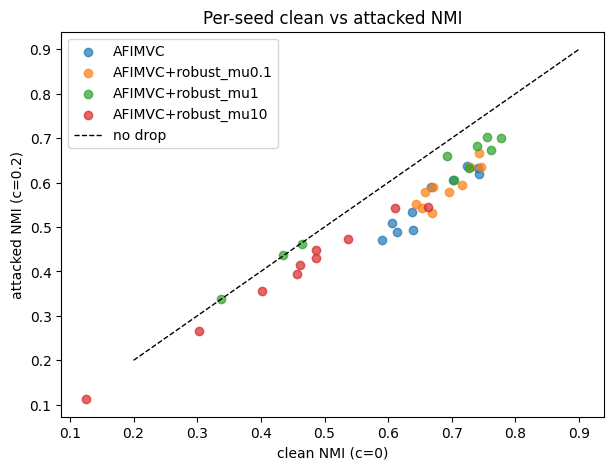

In [13]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 5))
for m in df.method.unique():
    sub = df[(df.method == m) & (df.c.isin([0, 0.2]))].pivot_table(index="seed", columns="c", values="NMI")
    ax.scatter(sub[0], sub[0.2], label=m, alpha=0.7)
lims = [0.2, 0.9]
ax.plot(lims, lims, "k--", lw=1, label="no drop")
ax.set_xlabel("clean NMI (c=0)"); ax.set_ylabel("attacked NMI (c=0.2)")
ax.set_title("Per-seed clean vs attacked NMI"); ax.legend()
plt.savefig("scatter_clean_vs_attacked.png", dpi=200); plt.show()

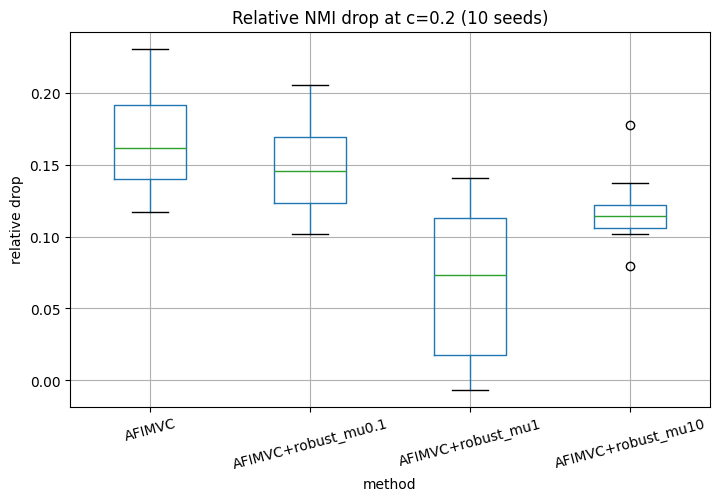

In [14]:
drop_rows = []
for m in df.method.unique():
    c0 = df[(df.method == m) & (df.c == 0)].set_index("seed")["NMI"]
    c2 = df[(df.method == m) & (df.c == 0.2)].set_index("seed")["NMI"]
    for s_ in c0.index:
        drop_rows.append(dict(method=m, rel_drop=(c0[s_] - c2[s_]) / c0[s_]))
dr = pd.DataFrame(drop_rows)
dr.boxplot(column="rel_drop", by="method", figsize=(8, 5), rot=15)
plt.suptitle(""); plt.title("Relative NMI drop at c=0.2 (10 seeds)")
plt.ylabel("relative drop"); plt.savefig("boxplot_rel_drop.png", dpi=200); plt.show()

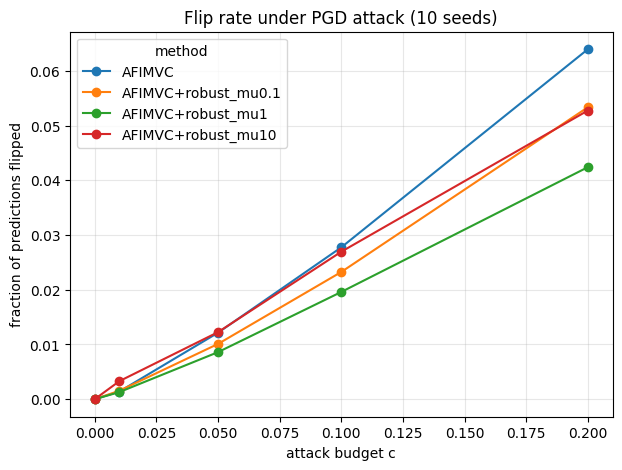

In [15]:
flip = df.groupby(["method", "c"])["FLIP"].mean().unstack(0)
flip.plot(marker="o", figsize=(7, 5))
plt.xlabel("attack budget c"); plt.ylabel("fraction of predictions flipped")
plt.title("Flip rate under PGD attack (10 seeds)"); plt.grid(alpha=0.3)
plt.savefig("flip_rate_vs_c.png", dpi=200); plt.show()

In [16]:
import shutil
from google.colab import files
for f in ["scatter_clean_vs_attacked.png", "boxplot_rel_drop.png", "flip_rate_vs_c.png"]:
    shutil.copy(f, f"outputs/{f}")
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>